In [1]:
import torch
import torch.nn as nn

# 1. Configurar el dispositivo (CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[SETUP] Dispositivo en uso: {device}")

# 2. Definir la arquitectura vacía (debe ser exactamente idéntica a la del entrenamiento)
class BaselineMLP128(nn.Module):
    def __init__(self):
        super(BaselineMLP128, self).__init__()
        self.flatten = nn.Flatten()
        self.classifier = nn.Sequential(
            nn.Linear(128 * 128 * 3, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.classifier(x)

# 3. Instanciar el modelo e importar los pesos entrenados desde el archivo .pth
WEIGHTS_PATH = "baseline_mlp_128.pth"

model = BaselineMLP128().to(device)
model.load_state_dict(torch.load(WEIGHTS_PATH, map_location=device))

# 4. Poner el modelo en modo evaluación (desactiva el Dropout para inferencia/test)
model.eval()

print(f"[OK] Modelo importado correctamente desde '{WEIGHTS_PATH}' y listo para usar.")

[SETUP] Dispositivo en uso: cpu
[OK] Modelo importado correctamente desde 'baseline_mlp_128.pth' y listo para usar.


In [2]:
import os
import random
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import datasets, transforms
import torchvision.transforms.functional as TF
from torch.utils.data import DataLoader

# Fijar semilla para que las transformaciones aleatorias sean reproducibles
random.seed(42)
np.random.seed(42)


class PerturbacionOpenCV:
    """
    Aplica transformaciones afines (traslación, rotación y zoom ligero) utilizando OpenCV.
    Emplea interpolación bilineal y bordes reflejados (BORDER_REFLECT_101) para evitar
    artefactos negros y preservar la nitidez del rostro.
    """
    def __init__(self, max_shift_px=16, max_angle_deg=18, scale_range=(0.92, 1.10)):
        self.max_shift = max_shift_px
        self.max_angle = max_angle_deg
        self.scale_range = scale_range

    def __call__(self, img_pil):
        # 1. Convertir imagen PIL a arreglo NumPy (H, W, C) y redimensionar a 128x128
        img_np = np.array(img_pil)
        img_np = cv2.resize(img_np, (128, 128), interpolation=cv2.INTER_AREA)
        h, w = img_np.shape[:2]
        centro = (w // 2, h // 2)

        # 2. Elegir aleatoriamente el tipo de perturbación (25% de probabilidad cada una)
        opcion = random.choice(["invariata", "traslacion", "rotacion_zoom", "combinada"])

        if opcion == "invariata":
            return Image.fromarray(img_np)

        # Inicializar parámetros por defecto
        angulo = 0.0
        escala = 1.0
        dx, dy = 0, 0

        if opcion == "traslacion":
            dx = random.randint(-self.max_shift, self.max_shift)
            dy = random.randint(-self.max_shift, self.max_shift)

        elif opcion == "rotacion_zoom":
            angulo = random.uniform(-self.max_angle, self.max_angle)
            escala = random.uniform(self.scale_range[0], self.scale_range[1])

        elif opcion == "combinada":
            angulo = random.uniform(-12.0, 12.0)
            escala = random.uniform(0.95, 1.08)
            dx = random.randint(-12, 12)
            dy = random.randint(-12, 12)

        # 3. Construir la matriz de transformación afín 2x3 con OpenCV
        M = cv2.getRotationMatrix2D(centro, angulo, escala)
        # Añadir la traslación (dx, dy) en la última columna de la matriz
        M[0, 2] += dx
        M[1, 2] += dy

        # 4. Aplicar la transformación con interpolación bilineal y relleno espejo en bordes
        img_mod = cv2.warpAffine(
            img_np,
            M,
            (w, h),
            flags=cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_REFLECT_101
        )

        # 5. Devolver como objeto PIL Image para continuar con el pipeline de PyTorch
        return Image.fromarray(img_mod)


# Pipeline completo listo para alimentar la red neuronal
transform_test_modificado = transforms.Compose([
    PerturbacionOpenCV(max_shift_px=16, max_angle_deg=18, scale_range=(0.92, 1.10)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
])

DATASET_PATH = "./fase_2/secondo_archiviio/sample_10k/"
test_dataset_mod = datasets.ImageFolder(
    root=os.path.join(DATASET_PATH, "test"),
    transform=transform_test_modificado
)
test_loader_mod = DataLoader(test_dataset_mod, batch_size=32, shuffle=False, num_workers=0)

print(f"[DATOS] Dataset de prueba perturbado listo: {len(test_dataset_mod)} imágenes.")

[DATOS] Dataset de prueba perturbado listo: 4005 imágenes.


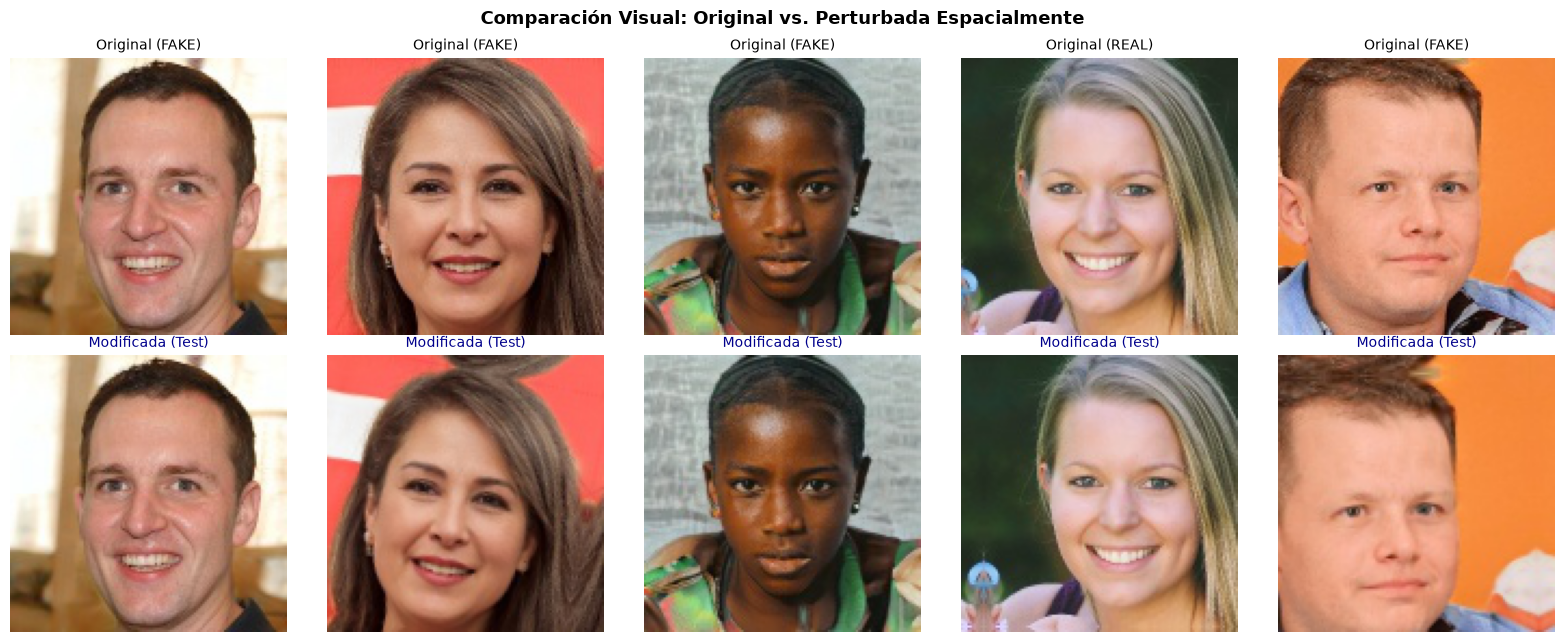

In [4]:
# Selección de 5 imágenes de ejemplo del conjunto de prueba
num_ejemplos = 5
indices_muestra = random.sample(range(len(test_dataset_mod)), num_ejemplos)

perturbador_visual = PerturbacionOpenCV(max_shift_px=16, max_angle_deg=18)

fig, axes = plt.subplots(2, num_ejemplos, figsize=(3.2 * num_ejemplos, 6.5))
fig.suptitle("Comparación Visual: Original vs. Perturbada Espacialmente", fontsize=13, fontweight="bold")

for col, idx in enumerate(indices_muestra):
    ruta_img, label_idx = test_dataset_mod.samples[idx]
    clase_nombre = test_dataset_mod.classes[label_idx].upper()
    
    # Imagen original redimensionada a 128x128
    img_orig = Image.open(ruta_img).convert("RGB").resize((128, 128))
    # Imagen modificada con la función
    img_mod = perturbador_visual(img_orig)
    
    # Fila superior: Original
    axes[0, col].imshow(img_orig)
    axes[0, col].set_title(f"Original ({clase_nombre})", fontsize=10)
    axes[0, col].axis("off")
    
    # Fila inferior: Modificada
    axes[1, col].imshow(img_mod)
    axes[1, col].set_title("Modificada (Test)", fontsize=10, color="darkblue")
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()

[TEST] Evaluando el modelo BaselineMLP128 sobre las imágenes perturbadas...

[RESULTADOS TRAS PERTURBACIÓN ESPACIAL]
              precision    recall  f1-score   support

        fake     0.7873    0.2720    0.4043      2000
        real     0.5607    0.9267    0.6986      2005

    accuracy                         0.5998      4005
   macro avg     0.6740    0.5993    0.5515      4005
weighted avg     0.6738    0.5998    0.5517      4005



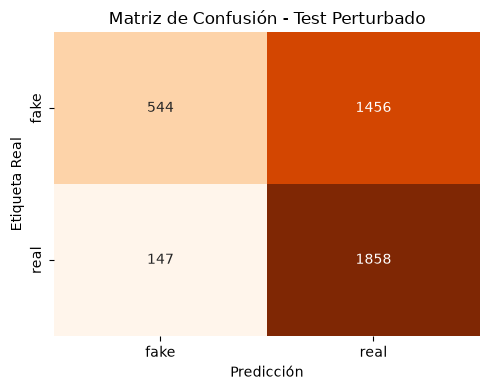

In [5]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

model.eval()
all_preds = []
all_labels = []

print("[TEST] Evaluando el modelo BaselineMLP128 sobre las imágenes perturbadas...")

with torch.no_grad():
    for images, labels in test_loader_mod:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

class_names = list(test_dataset_mod.class_to_idx.keys())
print("\n[RESULTADOS TRAS PERTURBACIÓN ESPACIAL]")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', xticklabels=class_names, yticklabels=class_names, cbar=False)
plt.xlabel("Predicción")
plt.ylabel("Etiqueta Real")
plt.title("Matriz de Confusión - Test Perturbado")
plt.tight_layout()
plt.show()